# Differentiable cut optimisation for a Z' search

**Hackathon notebook.** You will tune the selection of a Z' $\to t\bar t$ search by gradient descent, instead of scanning cut values by hand.

The big idea fits in one sentence. A hard cut has zero gradient, a soft cut has a useful one, and a useful gradient lets a computer improve the cut for you.

**How this notebook works**
- Cells marked **TODO** need you to fill in a few lines. Everything else is provided.
- The first plot is written out in full. Later plotting cells only describe what to draw; writing the plot is part of the exercise.
- We start from a flat table of events, read from the skimmed CMS Open Data samples in `data/`.

**Plan**
1. Look at the events and set up the data.
2. Baseline: optimise a hard cut by scanning.
3. See why gradients fail for a hard cut.
4. Replace the hard cut by a soft cut and optimise it by gradient ascent.
5. Build a soft histogram and optimise the bin edges.
6. Optimise several cuts together and compare with a brute-force scan.
7. Check the result honestly on events the optimiser never saw.
8. Stretch goals.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp


# JAX uses 32-bit floats by default. 64-bit avoids rounding surprises when we sum many small weights.
jax.config.update("jax_enable_x64", True)

plt.rcParams.update({"figure.figsize": (6.5, 3.8), "axes.grid": True, "grid.alpha": 0.3})

## 1. The events

Each event has three numbers.

- `m_ttbar`: the reconstructed mass of the top-quark pair, in GeV. A heavy resonance decaying to top quarks shows up as a bump on a falling background.
- `leading_jet_pt`: the transverse momentum of the highest-pT jet, in GeV.
- `met_pt`: the missing transverse momentum, in GeV.

Each event also has a **weight**. A weight says how many events of that kind we expect in real data. Summing the weights of the events that pass a selection gives the expected yield, called $s$ for signal and $b$ for background.

The significance we want to maximise is

$$Z = \frac{s}{\sqrt{b}} .$$

A larger $Z$ means the signal would stand out more against the background fluctuations.

### 1a. The samples

The folder `data/simple/` holds one `.npz` file per sample, skimmed from CMS Open Data NanoAOD. `signal` is a Z' boson with a mass of about 2 TeV decaying to $t\bar t$. The backgrounds are two $t\bar t$ samples (`ttbar`, `ttbar_lep`) and W boson production with jets (`wjets`). Each file is a flat table with one entry per event, and the event weights add up to the expected yield of that sample. The file `data.npz` holds real collision events with unit weights; we do not use it in this exercise.

`load_sample` function is given to you, which reads a single file at a time.

In [2]:
SAMPLES = {"signal": True, "ttbar": False, "ttbar_lep": False, "wjets": False}


def load_sample(name, is_signal):
    """Read one npz file: flat arrays, one entry per event."""
    d = np.load(f"../data/simple/{name}.npz")
    out = {k: d[k] for k in ("m_ttbar", "leading_jet_pt", "met_pt")}
    out["w"] = d["weight"]
    out["is_sig"] = np.full(len(d["weight"]), is_signal)
    return out


parts = [load_sample(name, is_sig) for name, is_sig in SAMPLES.items()]
events = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}

for name, p in zip(SAMPLES, parts):
    print(f"{name:10s}: {len(p['w']):7d} MC events, expected yield {float(p['w'].sum()):7.1f}")

signal    :   36294 MC events, expected yield  1128.9
ttbar     :  102171 MC events, expected yield  3863.4
ttbar_lep :   10397 MC events, expected yield   326.4
wjets     :      32 MC events, expected yield   398.8


### 1b. Scale the variables and split the events in two

Next, we should rescale the variables so that typical values are of order 1. That makes cut values and learning rates easier to reason about. `m_ttbar` and the jet pT are in TeV, the missing momentum in units of 100 GeV.

We should also split the events into a **training** half and a **test** half. The optimiser only sees the training half. The test half is kept for the honest check in section 7. Each half stands in for the full dataset, so after the split every weight must be scaled up by a factor 2, otherwise each half would only add up to half the expected yield.

We will store the signal and background weights in separate arrays, `w_s` and `w_b`. A weight is zero in the array of the other class. That way `w_s * selection` summed over events is the signal yield, and the same for the background.

**TODO.** Build the two datasets.

1. `X_all`: a matrix of shape `(n_events, 3)` with one row per event and one column per feature, each feature divided by its entry in `SCALE` (`np.stack` helps).
2. `order`, `half`: shuffle the event indices with `np.random.default_rng(0).permutation(...)` and split them in the middle.
3. `make_dataset(indices)` builds one half:
   - multiply the weights of the events in `indices` by `factor = len(order) / len(indices)`;
   - split them into `w_s` (the weight for signal events, 0 for background) and `w_b` (the other way round), using `events["is_sig"]` and `np.where`;
   - return `{"X": ..., "w_s": ..., "w_b": ...}`, each converted with `jnp.array`.
4. `train`, `test`: call `make_dataset` on the first and the second half of `order`. This is a slicing problem!

The print at the end is your check. The first number is only how many simulated events landed in each half (about 74 000). The physics numbers are the weighted sums: each half should report an expected yield of roughly 1130 signal and 4590 background events.

In [3]:
SCALE = {"m_ttbar": 1000.0, "leading_jet_pt": 1000.0, "met_pt": 100.0}
FEATURES = ["m_ttbar", "leading_jet_pt", "met_pt"]

X_all = np.stack([events[f] / SCALE[f] for f in FEATURES], axis=1)          # step 1

order = np.random.default_rng(0).permutation(len(X_all))                   # step 2
half = len(order) // 2


def make_dataset(indices):
    factor = len(order) / len(indices)           # step 3: each half stands in for the full expected yield
    is_sig, w = events["is_sig"][indices], events["w"][indices] * factor
    return {
        "X": jnp.array(X_all[indices]),
        "w_s": jnp.array(np.where(is_sig, w, 0.0)),
        "w_b": jnp.array(np.where(is_sig, 0.0, w)),
    }


train = make_dataset(order[:half])                                          # step 4
test = make_dataset(order[half:])

print(f"train: {train['X'].shape[0]} MC events, expected yield: {float(train['w_s'].sum()):.1f} signal, {float(train['w_b'].sum()):.0f} background")
print(f"test:  {test['X'].shape[0]} MC events, expected yield: {float(test['w_s'].sum()):.1f} signal, {float(test['w_b'].sum()):.0f} background")

train: 74447 MC events, expected yield: 1124.5 signal, 4570 background
test:  74447 MC events, expected yield: 1133.2 signal, 4607 background


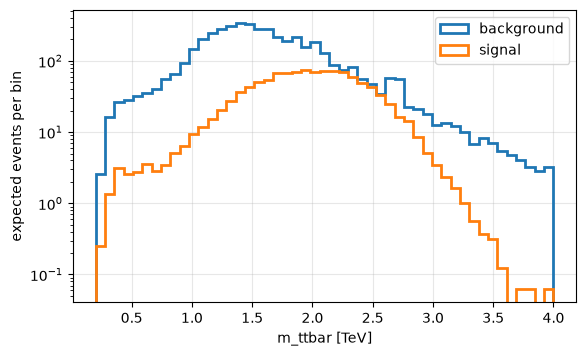

In [4]:
bins = np.linspace(0.2, 4.0, 50)
x_m = np.asarray(train["X"][:, 0])

fig, ax = plt.subplots()
ax.hist(x_m, bins=bins, weights=np.asarray(train["w_b"]), histtype="step", lw=2, label="background")
ax.hist(x_m, bins=bins, weights=np.asarray(train["w_s"]), histtype="step", lw=2, label="signal")
ax.set_yscale("log")
ax.set_xlabel("m_ttbar [TeV]")
ax.set_ylabel("expected events per bin")
ax.legend()
plt.show()

**Question.** Looking at the plot, roughly where would you put a cut on `m_ttbar`? Enter your guess in the cell below (in TeV). We will compare it with the optimiser's answer later.

In [5]:
MY_MTT_CUT_GUESS = 1.5

## 2. Baseline: a hard cut and a scan

The data is ready, so we can start analysing. The simplest possible analysis is a single hard cut: we will keep an event if `m_ttbar` is above some value and throw it away otherwise, and we will look for the cut value that maximises $Z$ by brute force, simply trying many values.

To prepare for what comes later, we will not select events the way you are used to, with a boolean mask like `x[x > cut]`. Instead we keep every event and give it a **selection weight** between 0 and 1: multiplying an event's weight by 1 keeps it, by 0 drops it. For a hard cut that number is exactly 0 or 1.

Why do it this way? JAX prefers arrays that keep a fixed size: filtering would change the array shape with every cut value and force `jax.jit` to recompile. More importantly, a selection written as one number per event is something we can later make **smooth**, and that is the key idea of the whole notebook.

**TODO.** Fill in `yields` below: given the selection weights `sel`, it returns the expected yields $s = \sum_i w_{s,i} \, \mathrm{sel}_i$ and $b = \sum_i w_{b,i} \, \mathrm{sel}_i$.

In [6]:
B_FLOOR = 1.0     # explained in the note below


def yields(sel, d):
    """Expected signal and background after a selection.

    sel is one number per event: 1 keeps the event, 0 drops it, values in between keep part of it.
    """
    return jnp.sum(d["w_s"] * sel), jnp.sum(d["w_b"] * sel)

**A note on `B_FLOOR`.** The simulation has a finite number of background events. If a selection leaves almost none, $b$ can end up close to zero by accident, and $s/\sqrt{b}$ becomes enormous. That is a statistical accident of the simulation, not real sensitivity, and an optimiser will happily hunt for it. Adding one expected background event inside the square root removes the problem. It makes no visible difference when $b$ is large.

**TODO.** Fill in the two functions below.

- `significance(s, b)` returns $s/\sqrt{b + b_{\text{floor}}}$, with `B_FLOOR` defined above. The floor is explained right after this cell.
- `Z_hard(cut, d)` applies the hard cut `m_ttbar > cut` to dataset `d` and returns the significance. The `m_ttbar` values are in `d["X"][:, 0]`.

Then use them in the scan cell below: evaluate the hard-cut $Z$ on a fine grid of cut values and pick the one where it is largest. The prints compare the result with your guess.

In [7]:
def significance(s, b):
    return s / jnp.sqrt(b + B_FLOOR)


def Z_hard(cut, d):
    sel = jnp.where(d["X"][:, 0] > cut, 1.0, 0.0)
    s, b = yields(sel, d)
    return significance(s, b)

In [8]:
cuts = np.linspace(0.3, 3.0, 111)
Z_scan = np.array([float(Z_hard(c, train)) for c in cuts])
best_cut = cuts[Z_scan.argmax()]

print(f"best hard cut from the scan: m_ttbar > {best_cut:.2f} TeV, Z = {Z_scan.max():.2f}")
print(f"your guess:                  m_ttbar > {MY_MTT_CUT_GUESS:.2f} TeV, Z = {float(Z_hard(MY_MTT_CUT_GUESS, train)):.2f}")

best hard cut from the scan: m_ttbar > 1.67 TeV, Z = 19.65
your guess:                  m_ttbar > 1.50 TeV, Z = 19.12


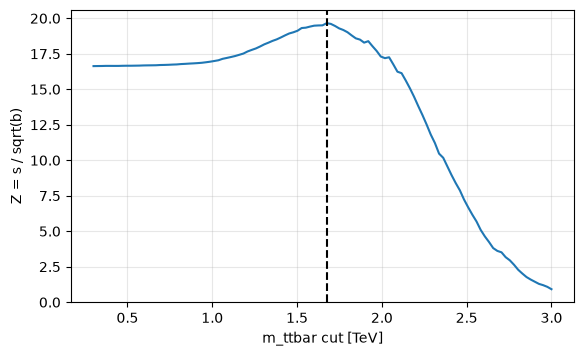

In [9]:
fig, ax = plt.subplots()
ax.plot(cuts, Z_scan)
ax.axvline(best_cut, color="k", ls="--")
ax.set_xlabel("m_ttbar cut [TeV]")
ax.set_ylabel("Z = s / sqrt(b)")
plt.show()

This works for one cut. With three cuts and a fine grid it already needs hundreds of thousands of evaluations. With a dozen cuts it is hopeless. We want to follow the slope of $Z$ uphill instead of visiting every point.

## 3. Why a hard cut cannot be optimised by gradient

Before building anything new, we should check what the gradient of our hard cut looks like. JAX can differentiate a function for us. Look up in the [JAX documentation](https://docs.jax.dev/) how to take the gradient of a function, and evaluate the derivative of `Z_hard` with respect to the cut at 1.5 TeV, where the curve above clearly has a slope.

In [10]:
grad_hard = jax.grad(Z_hard)(1.5, train)
print("dZ/dcut at 1.5 TeV:", float(grad_hard))

dZ/dcut at 1.5 TeV: 0.0


**Question.** The plot above shows a clear slope at 1.5 TeV, yet the gradient is exactly zero. Why? Think about what happens to a single event when the cut moves by a tiny amount.

## 4. A soft cut

The fix is to replace the step function by a smooth one, the **sigmoid**:

$$ \text{sel}(x) = \sigma\!\left(\frac{x - c}{\tau}\right), \qquad \sigma(u) = \frac{1}{1 + e^{-u}} . $$

Far above the cut the selection weight is close to 1, far below it is close to 0, and near the cut it changes smoothly. The number $\tau$ is the **width** of the transition. A small $\tau$ looks like a hard cut. A large $\tau$ is very blurry.

**TODO.** Write `soft_cut` and `Z_soft`. Use `jax.nn.sigmoid`.

In [11]:
def soft_cut(x, cut, tau):
    return jax.nn.sigmoid((x - cut) / tau)


def Z_soft(cut, d, tau):
    sel = soft_cut(d["X"][:, 0], cut, tau)
    s, b = yields(sel, d)
    return significance(s, b)

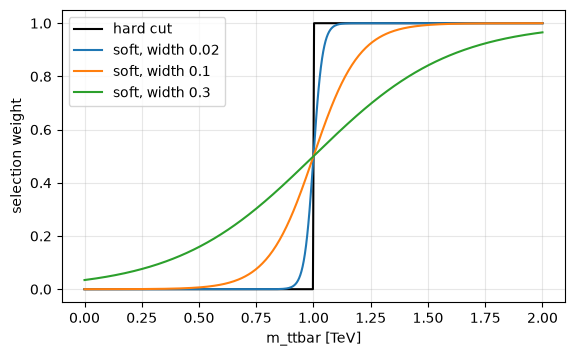

In [12]:
xs = np.linspace(0.0, 2.0, 400)
fig, ax = plt.subplots()
ax.plot(xs, (xs > 1.0).astype(float), "k", label="hard cut")
for tau in [0.02, 0.1, 0.3]:
    ax.plot(xs, soft_cut(xs, 1.0, tau), label=f"soft, width {tau}")
ax.set_xlabel("m_ttbar [TeV]")
ax.set_ylabel("selection weight")
ax.legend()
plt.show()

Now the significance as a function of the cut, for the hard cut and for soft cuts of different widths.

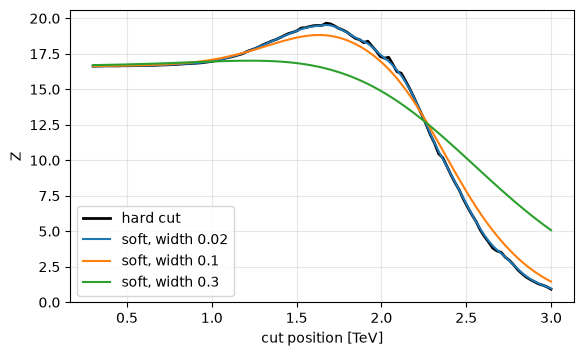

In [13]:
fig, ax = plt.subplots()
ax.plot(cuts, Z_scan, "k", lw=2, label="hard cut")
for tau in [0.02, 0.1, 0.3]:
    Zs = np.array([float(Z_soft(c, train, tau)) for c in cuts])
    ax.plot(cuts, Zs, label=f"soft, width {tau}")
ax.set_xlabel("cut position [TeV]")
ax.set_ylabel("Z")
ax.legend()
plt.show()

The soft curves are smooth and have a slope everywhere. Check that the gradient now comes out non-zero: evaluate the derivative of `Z_soft` with respect to the cut at 1.0, 1.5 and 2.4 TeV, with width 0.1.

In [14]:
print("dZ/dcut at 1.0 TeV:", float(jax.grad(Z_soft)(1.0, train, 0.1)))
print("dZ/dcut at 1.5 TeV:", float(jax.grad(Z_soft)(1.5, train, 0.1)))
print("dZ/dcut at 2.4 TeV:", float(jax.grad(Z_soft)(2.4, train, 0.1)))

dZ/dcut at 1.0 TeV: 1.9528042078018188
dZ/dcut at 1.5 TeV: 2.559358596801758
dZ/dcut at 2.4 TeV: -21.151315689086914


### Gradient ascent

To maximise $Z$ we repeat one step many times:

$$ p \leftarrow p + \eta \, \frac{\partial Z}{\partial p} . $$

Here $p$ holds the parameters being tuned and $\eta$ is the **learning rate**. Each step moves the parameters a little way uphill.

**TODO.** Write `gradient_ascent` from scratch. Build the gradient function of `f` (wrap it in `jax.jit` so the loop runs fast), start from `p0`, repeat the update step `n_steps` times, and store every value of `p` along the way. Return the final `p` and the stored values as a `np.array`, so we can plot the journey.

In [15]:
def gradient_ascent(f, p0, lr, n_steps):
    grad_f = jax.jit(jax.grad(f))
    p = p0
    path = [p]
    for _ in range(n_steps):
        p = p + lr * grad_f(p)
        path.append(p)
    return p, np.array(path)

In [16]:
TAU = 0.1

p_opt, path = gradient_ascent(lambda c: Z_soft(c, train, TAU), jnp.array(0.8), lr=0.02, n_steps=150)

print(f"optimised cut:  m_ttbar > {float(p_opt):.2f} TeV")
print(f"soft Z at that cut: {float(Z_soft(p_opt, train, TAU)):.2f}")
print(f"HARD Z at that cut: {float(Z_hard(p_opt, train)):.2f}   (scan optimum: {Z_scan.max():.2f} at {best_cut:.2f} TeV)")

optimised cut:  m_ttbar > 1.63 TeV
soft Z at that cut: 18.82
HARD Z at that cut: 19.49   (scan optimum: 19.65 at 1.67 TeV)


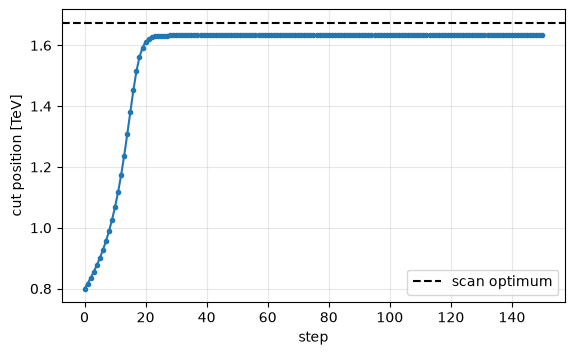

In [17]:
fig, ax = plt.subplots()
ax.plot(path, ".-")
ax.axhline(best_cut, color="k", ls="--", label="scan optimum")
ax.set_xlabel("step")
ax.set_ylabel("cut position [TeV]")
ax.legend()
plt.show()

**Things to try**
- Change the learning rate. What happens with `lr=0.002`? With `lr=0.2`?
- Change the starting point `0.8` to `0.4` and to `2.4`. Do you reach the same answer?
- Change `TAU` to `0.02`. The optimised cut lands even closer to the scan optimum. Why can we afford such a small width with this many events?
- Change `TAU` to `0.5`. The optimum moves. Which cut value do you get now, and what is its **hard** $Z$?

The width $\tau$ is a trade-off. If it is too small the gradient vanishes away from the cut. If it is too large the soft cut no longer resembles the hard cut you will actually use. The loop below shows the effect for a range of widths.

In [18]:
print(" width |  optimised cut | hard Z at that cut")
for tau in [0.02, 0.05, 0.1, 0.2, 0.4]:
    p, _ = gradient_ascent(lambda c: Z_soft(c, train, tau), jnp.array(1.0), lr=0.02, n_steps=300)
    print(f" {tau:5.2f} | {float(p):14.2f} | {float(Z_hard(p, train)):.2f}")

 width |  optimised cut | hard Z at that cut


  0.02 |           1.68 | 19.67


  0.05 |           1.65 | 19.50


  0.10 |           1.63 | 19.49


  0.20 |           1.51 | 19.12


  0.40 |           0.69 | 16.71


## 5. A soft histogram and its bin edges

So far we have optimised a single cut. A real analysis fits a histogram, not a single cut, and a histogram has bin edges, which are cuts too. We should be able to make a histogram differentiable in exactly the same way.

An event belongs to bin $i$ if it is above edge $e_i$ and below edge $e_{i+1}$. To make that differentiable we use a **binned kernel density estimate (bKDE)**, the same construction real differentiable-analysis tools use: replace each event by a narrow Gaussian kernel of width $h$, the **bandwidth**, centred on its value, and let a bin's content be the area of the kernel that falls inside the bin. With the Gaussian CDF $\Phi$ (available as `jax.scipy.stats.norm.cdf`) that is

$$ \text{membership}_i(x) = \Phi\!\left(\frac{x - e_i}{h}\right) - \Phi\!\left(\frac{x - e_{i+1}}{h}\right), $$

with $\Phi = 1$ for the lowest edge (at $-\infty$) and $\Phi = 0$ for the highest edge (at $+\infty$). The bandwidth plays the role the width $\tau$ played for the soft cut: small is faithful to the sharp histogram but has vanishing gradients, large blurs events across bins. Summing the signal weights times the membership gives the signal yield of each bin, and the same for the background.

Each bin has its own significance $s_i/\sqrt{b_i}$. Independent bins combine in quadrature:

$$ Z = \sqrt{\sum_i \frac{s_i^2}{b_i}} . $$

**TODO.** Complete `soft_bin_membership` and `Z_binned`. The `edges` array holds the inner edges. Sorting it keeps the bins in order even if the optimiser moves two edges past each other.

In [19]:
def soft_bin_membership(x, edges, bandwidth):
    """Array of shape (n_events, n_bins) saying how much each event belongs to each bin."""
    above = jax.scipy.stats.norm.cdf((x[:, None] - edges[None, :]) / bandwidth)   # shape (n_events, n_edges)
    ones = jnp.ones((x.shape[0], 1))
    zeros = jnp.zeros((x.shape[0], 1))
    cum = jnp.concatenate([ones, above, zeros], axis=1)               # shape (n_events, n_edges + 2)
    return cum[:, :-1] - cum[:, 1:]


def Z_binned(edges, d, bandwidth):
    m = soft_bin_membership(d["X"][:, 0], jnp.sort(edges), bandwidth)
    s = d["w_s"] @ m                  # signal yield in each bin
    b = d["w_b"] @ m                  # background yield in each bin
    return jnp.sqrt(jnp.sum(s**2 / (b + B_FLOOR)))

In [20]:
BANDWIDTH = 0.1
edges0 = jnp.array([0.8, 1.4, 2.0])          # starting edges: four bins

edges_opt, edge_path = gradient_ascent(lambda e: Z_binned(e, train, BANDWIDTH), edges0, lr=0.02, n_steps=300)
edges_opt = jnp.sort(edges_opt)

print("starting edges :", np.round(np.asarray(edges0), 2), f"  Z = {float(Z_binned(edges0, train, BANDWIDTH)):.2f}")
print("optimised edges:", np.round(np.asarray(edges_opt), 2), f"  Z = {float(Z_binned(edges_opt, train, BANDWIDTH)):.2f}")
print(f"best single hard cut for comparison: Z = {Z_scan.max():.2f}")

starting edges : [0.8 1.4 2. ]   Z = 20.46
optimised edges: [1.19 1.66 2.01]   Z = 20.74
best single hard cut for comparison: Z = 19.65


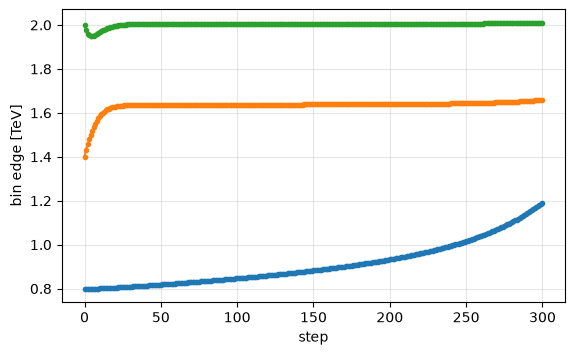

In [21]:
fig, ax = plt.subplots()
ax.plot(edge_path, ".-")
ax.set_xlabel("step")
ax.set_ylabel("bin edge [TeV]")
plt.show()

**Question.** The binned $Z$ is at least as large as the single-cut $Z$ of the scan. Why can adding bins never make the sensitivity worse?

**Things to try**
- Use five or six bins by giving more starting edges.
- Where do the optimised edges end up? Do they pile up near the signal region?
- Evaluate the optimised edges with a very small `BANDWIDTH`, such as `0.01`, to see what the histogram looks like with sharp bins.

## 6. Several cuts at once

So far we tuned one number. The real advantage of gradients appears when many numbers are tuned together.

We will now optimise two cuts at once: one on `m_ttbar` and one on the leading jet pT. A selection that passes both cuts has weight $\sigma_1 \times \sigma_2$, the product of two soft cuts. Each cut has its own width.

**TODO.** Write all four functions below. `soft_selection` and `hard_selection` return one number per event; the array `cuts` has one entry per cut and applies to the first `len(cuts)` columns of `X`, and the soft version takes one width per cut. `Z_joint_soft` and `Z_joint_hard` combine them with `yields` and `significance`, as before.

In [22]:
def soft_selection(X, cuts, taus):
    return jnp.prod(jax.nn.sigmoid((X[:, :cuts.shape[0]] - cuts[None, :]) / taus[None, :]), axis=1)


def hard_selection(X, cuts):
    return jnp.all(X[:, :cuts.shape[0]] > cuts[None, :], axis=1).astype(float)


def Z_joint_soft(cuts, d, taus):
    s, b = yields(soft_selection(d["X"], cuts, taus), d)
    return significance(s, b)


def Z_joint_hard(cuts, d):
    s, b = yields(hard_selection(d["X"], cuts), d)
    return significance(s, b)

For comparison we need the brute-force answer. The helper `scan_2d` is provided; you choose the two grids, run the scan and locate its maximum.

In [23]:
def scan_2d(d, grid1, grid2):
    one_row = jax.jit(jax.vmap(lambda c2, c1: Z_joint_hard(jnp.array([c1, c2]), d), in_axes=(0, None)))
    return np.array([one_row(jnp.asarray(grid2), c1) for c1 in grid1])       # shape (len(grid1), len(grid2))


grid_m = np.linspace(0.3, 2.6, 45)
grid_jet = np.linspace(0.15, 1.2, 50)
Z_grid = scan_2d(train, grid_m, grid_jet)

i, j = np.unravel_index(Z_grid.argmax(), Z_grid.shape)
print(f"brute-force scan ({Z_grid.size} points): m_ttbar > {grid_m[i]:.2f} TeV, leading jet pT > {1000*grid_jet[j]:.0f} GeV, Z = {Z_grid.max():.2f}")

brute-force scan (2250 points): m_ttbar > 0.82 TeV, leading jet pT > 621 GeV, Z = 21.73


In [24]:
TAUS = jnp.array([0.1, 0.05])
cuts0 = jnp.array([0.8, 0.2])

cuts_opt, cut_path = gradient_ascent(lambda c: Z_joint_soft(c, train, TAUS), cuts0, lr=0.01, n_steps=500)

print(f"gradient ascent: m_ttbar > {float(cuts_opt[0]):.2f} TeV, leading jet pT > {1000*float(cuts_opt[1]):.0f} GeV")
print(f"soft Z = {float(Z_joint_soft(cuts_opt, train, TAUS)):.2f},  hard Z = {float(Z_joint_hard(cuts_opt, train)):.2f}")

gradient ascent: m_ttbar > 0.81 TeV, leading jet pT > 637 GeV
soft Z = 20.43,  hard Z = 21.75


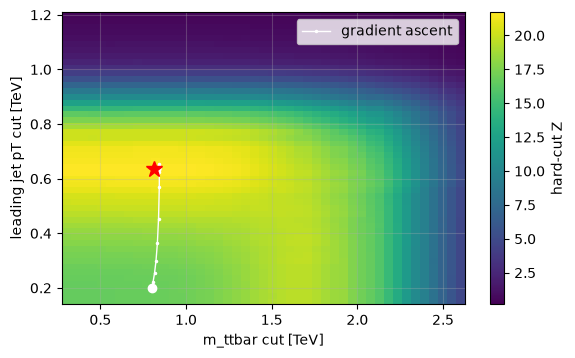

In [25]:
fig, ax = plt.subplots()
mesh = ax.pcolormesh(grid_m, grid_jet, Z_grid.T, shading="auto")
ax.plot(cut_path[:, 0], cut_path[:, 1], "w.-", ms=3, lw=1, label="gradient ascent")
ax.plot(*cut_path[0], "wo")
ax.plot(*cut_path[-1], "r*", ms=12)
ax.set_xlabel("m_ttbar cut [TeV]")
ax.set_ylabel("leading jet pT cut [TeV]")
fig.colorbar(mesh, label="hard-cut Z")
ax.legend()
plt.show()

**Questions**: write your answers in the markdown cell below (double-click it to edit).

- How many times did the brute-force scan evaluate $Z$, and how many gradient steps did the optimiser need?
- Now imagine ten cuts instead of two. How would the cost of each method change?
- Does the jet pT cut help at all compared with the `m_ttbar` cut alone? Compare the two best $Z$ values.

*Your answers:*

1. The brute-force scan evaluated $Z$ at 2250 grid points; gradient ascent used about 500 steps (each step costs one value-plus-gradient evaluation).
2. With ten cuts a comparable grid needs $\sim 45^{10}$ evaluations, which is impossible, while gradient ascent still needs only hundreds of steps; its cost grows roughly linearly with the number of parameters.
3. Yes: the best single cut gave $Z \approx 19.7$, the joint optimum $Z \approx 21.7$. Note how the optimal m_ttbar cut moved from 1.67 TeV to about 0.8 TeV once the jet-pT cut existed: cuts must be optimised together, not one after the other.

**Things to try**: the two cells below are yours.

In [26]:
TAUS3 = jnp.array([0.1, 0.05, 0.1])
cuts0_3 = jnp.array([0.8, 0.2, 0.5])

cuts3, _ = gradient_ascent(lambda c: Z_joint_soft(c, train, TAUS3), cuts0_3, lr=0.01, n_steps=500)
print("optimised cuts (m_ttbar [TeV], jet pT [TeV], MET [100 GeV]):", np.round(np.asarray(cuts3), 2))
print(f"hard Z = {float(Z_joint_hard(cuts3, train)):.2f}   (two cuts gave {float(Z_joint_hard(cuts_opt, train)):.2f})")

optimised cuts (m_ttbar [TeV], jet pT [TeV], MET [100 GeV]): [0.81 0.64 0.12]
hard Z = 21.75   (two cuts gave 21.75)


In [27]:
for start in [(0.6, 0.3), (1.6, 0.2), (0.8, 2.5)]:
    c, _ = gradient_ascent(lambda c: Z_joint_soft(c, train, TAUS), jnp.array(start), lr=0.01, n_steps=500)
    print(f"start {start}: ends at m_ttbar > {float(c[0]):.2f} TeV, jet pT > {1000*float(c[1]):.0f} GeV, hard Z = {float(Z_joint_hard(c, train)):.2f}")

start (0.6, 0.3): ends at m_ttbar > 0.81 TeV, jet pT > 637 GeV, hard Z = 21.75


start (1.6, 0.2): ends at m_ttbar > 0.81 TeV, jet pT > 637 GeV, hard Z = 21.75


start (0.8, 2.5): ends at m_ttbar > 0.80 TeV, jet pT > 2500 GeV, hard Z = 0.00


## 7. Using the optimised cuts: an honest evaluation

The optimisation is done. In a real analysis the next step is to **freeze** the optimised cuts, which from here on are just fixed numbers in the event selection, and to quote the expected sensitivity of that selection. This section is about which number you are allowed to quote.

Everything so far used the training events, both for choosing the cuts and for reporting $Z$. If you have ever trained a machine-learning model, you know the trap: a model fitted to a training set learns the real patterns *and* the random noise of that particular set, so its score on its own training data is too optimistic, and performance is always quoted on a held-out set. Our cut values are no different: they are parameters tuned on a sample, and the optimiser will exploit that sample's random fluctuations. The same rule applies: tune on the training half, then evaluate the final **hard** cuts on the test half, which the optimiser has never seen; that $Z$ is the one you report.

With 75 000 training events and only two tuned cuts, this overfitting (the amount by which the training $Z$ overshoots the test $Z$) is tiny, so we will make it visible by shrinking the training sample. The helper `subsample` keeps `n` random training events and rescales their weights so that the total expected yield stays the same: every subsample describes **exactly the same physics**, only with worse simulation statistics. Any gap between the training $Z$ and the test $Z$ is therefore not physics: it is the optimiser fooling itself on fluctuations, and measuring the gap as a function of `n` shows how much the quoted sensitivity would have been inflated.

In [28]:
def subsample(d, n, seed=0):
    N = d["X"].shape[0]
    indices = np.random.default_rng(seed).choice(N, n, replace=False)
    f = N / n
    return {"X": d["X"][indices], "w_s": d["w_s"][indices] * f, "w_b": d["w_b"][indices] * f}

**TODO.** Build the study in the cell below.

1. `tune_and_evaluate(d_train, d_test)`: tune the two cuts by gradient ascent on `d_train` (the settings from section 6 work), then return the cuts and the **hard-cut** $Z$ on `d_train` and on `d_test`.
2. Pick a few training sizes, from a few hundred events up to the full half. For each size, and for each of the ten seeds: `subsample` the training half to that size, run `tune_and_evaluate`, and collect the two $Z$ values.
3. The print reports the average $Z$ on the small training sample and on the full test half, for each size.

If everything works, the gap between the two numbers should shrink as the training sample grows.

In [29]:
def tune_and_evaluate(d_train, d_test, seed_cuts=jnp.array([0.8, 0.2])):
    cuts, _ = gradient_ascent(lambda c: Z_joint_soft(c, d_train, TAUS), seed_cuts, lr=0.01, n_steps=500)   # step 1
    return cuts, float(Z_joint_hard(cuts, d_train)), float(Z_joint_hard(cuts, d_test))


for n in [300, 1000, 10_000, 70_000]:                                        # step 2
    z_tr, z_te = [], []
    for seed in range(10):
        small = subsample(train, n, seed=seed)
        _, a, b = tune_and_evaluate(small, test)
        z_tr.append(a)
        z_te.append(b)
    print(f"n_train = {n:7d}:  Z on training sample = {np.mean(z_tr):.2f},  Z on test sample = {np.mean(z_te):.2f}")   # step 3

n_train =     300:  Z on training sample = 22.07,  Z on test sample = 19.88


n_train =    1000:  Z on training sample = 21.86,  Z on test sample = 20.14


n_train =   10000:  Z on training sample = 22.00,  Z on test sample = 21.03


n_train =   70000:  Z on training sample = 21.71,  Z on test sample = 21.19


**Questions**: write your answers in the markdown cell below (double-click it to edit).

- For which training sizes is the training $Z$ larger than the test $Z$? What does that gap tell you?
- With only a few parameters the gap stays small for large samples. What would you expect if you tuned hundreds of parameters on the same sample?
- The brute-force scan overfits in exactly the same way. Is gradient-based tuning more or less vulnerable to it?

*Your answers:*

1. The training $Z$ is larger on average at every size; the gap (about +2 at $n = 300$, +0.5 at $n = 70\,000$) is the optimiser exploiting the random fluctuations of the small sample: sensitivity that is not real.
2. The gap grows with the number of tuned parameters: hundreds of parameters can memorise far more of the sample's noise, so the training $Z$ would be badly inflated even for large samples.
3. Equally vulnerable: the scan also selects whichever grid point profits most from the fluctuations. Overfitting comes from optimising anything flexible on a finite sample, not from using gradients.

## Wrap-up

You have gone from a cut scan to a small differentiable analysis.

- A hard cut has no useful gradient. A soft cut does.
- The width of the soft cut trades a usable gradient against faithfulness to the hard cut.
- Binning can be made differentiable the same way, so bin edges become parameters.
- Many parameters can be tuned together by following one gradient.
- Always evaluate the final **hard** selection on events that were not used for tuning.

This is the same idea that full-scale differentiable analyses apply to a complete selection, a neural-network classifier and a statistical model together.

## 8. Stretch goals

Pick whichever interests you. Each uses only functions you have already written.

### A. A better significance, with a background uncertainty

The formula $s/\sqrt{b}$ is a simplification. Two common improvements:

$$ Z_{\text{Asimov}} = \sqrt{2\left[(s+b)\ln\!\left(1 + \frac{s}{b}\right) - s\right]}, \qquad
Z_{\delta} = \frac{s}{\sqrt{b + (\delta\, b)^2}} . $$

The second one includes a fractional uncertainty $\delta$ on the background yield, for example $\delta = 0.1$ for 10 percent.

**Task.** Redefine `significance` with each formula in turn and rerun the single-cut optimisation of section 4. Does the optimal cut move? In which direction, and why?

In [30]:
def significance_asimov(s, b):
    b = b + B_FLOOR
    return jnp.sqrt(2.0 * ((s + b) * jnp.log1p(s / b) - s))


def make_significance_delta(delta):
    def sig(s, b):
        return s / jnp.sqrt(b + (delta * b) ** 2 + B_FLOOR)
    return sig


def best_cut_with(sig_fn, tau=0.1):
    def f(c):
        s, b = yields(soft_cut(train["X"][:, 0], c, tau), train)
        return sig_fn(s, b)
    p, _ = gradient_ascent(f, jnp.array(1.0), lr=0.02, n_steps=300)
    return float(p)


print(f"s/sqrt(b)         : best cut {best_cut_with(significance):.2f} TeV")
print(f"Asimov            : best cut {best_cut_with(significance_asimov):.2f} TeV")
for delta in [0.05, 0.1, 0.3]:
    print(f"delta = {delta:4.2f}       : best cut {best_cut_with(make_significance_delta(delta)):.2f} TeV")

s/sqrt(b)         : best cut 1.63 TeV


Asimov            : best cut 1.59 TeV


delta = 0.05       : best cut 2.04 TeV


delta = 0.10       : best cut 2.10 TeV


delta = 0.30       : best cut 2.13 TeV


### B. A learned selection instead of rectangular cuts

Cuts on m_ttbar, the jet pT and MET make a rectangular box in feature space. A **linear discriminant** can tilt the boundary:

$$ \text{sel}(\vec{x}) = \sigma\!\left(\vec{w}\cdot\vec{x} + w_0\right) . $$

The three numbers in $\vec w$ and the offset $w_0$ are the parameters. Tune them directly against $Z$ with the same gradient ascent. This is a one-neuron neural network trained on the physics goal instead of on a generic loss.

**Task.** Write `Z_linear(params, d)` with `params = [w1, w2, w3, w0]`. Tune it, then evaluate the corresponding hard selection (`w . x + w0 > 0`) on the test half and compare with the rectangular cuts of section 6. This needs many more steps than a single cut, so be patient and plot $Z$ against the step number if you want to see it converge.

In [31]:
def Z_linear(params, d):
    score = d["X"] @ params[:3] + params[3]
    s, b = yields(jax.nn.sigmoid(score), d)
    return significance(s, b)


def Z_linear_hard(params, d):
    score = d["X"] @ params[:3] + params[3]
    s, b = yields(jnp.where(score > 0.0, 1.0, 0.0), d)
    return significance(s, b)


params0 = jnp.array([2.0, 1.0, 0.5, -3.0])
params_opt, _ = gradient_ascent(lambda p: Z_linear(p, train), params0, lr=0.2, n_steps=3000)

print("weights and offset:", np.round(np.asarray(params_opt), 2))
print(f"hard Z on train: {float(Z_linear_hard(params_opt, train)):.2f},  on test: {float(Z_linear_hard(params_opt, test)):.2f}")

weights and offset: [  0.69  32.37   2.1  -26.69]
hard Z on train: 22.96,  on test: 22.93
